# SoC estimation: results walkthrough

Every number and figure here is read from `results/` (produced by `scripts/run_all.py`), so this notebook
cannot drift from the code. Test-set numbers are on held-out EPA cycles (US06, HWFET, UDDS); 10 °C and
-10 °C are also unseen temperatures. RMSE and errors are in SoC percentage points.

In [1]:
import json
from pathlib import Path
import numpy as np
from IPython.display import Image, Markdown, display

R = Path('..') / 'results'
load = lambda f: json.loads((R / f).read_text())
TEMPS = [25, 10, 0, -10, -20]

def by_T(res, prefix, scenario='realistic', key='rmse', agg=np.mean):
    return [agg([r[key] for r in res if r['scenario'] == scenario and r['temp'] == T
                 and r['method'].startswith(prefix)]) for T in TEMPS]

def table(rows, header):
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
    lines += ['| ' + ' | '.join(r) + ' |' for r in rows]
    display(Markdown(chr(10).join(lines)))

## 1. Model building and verification

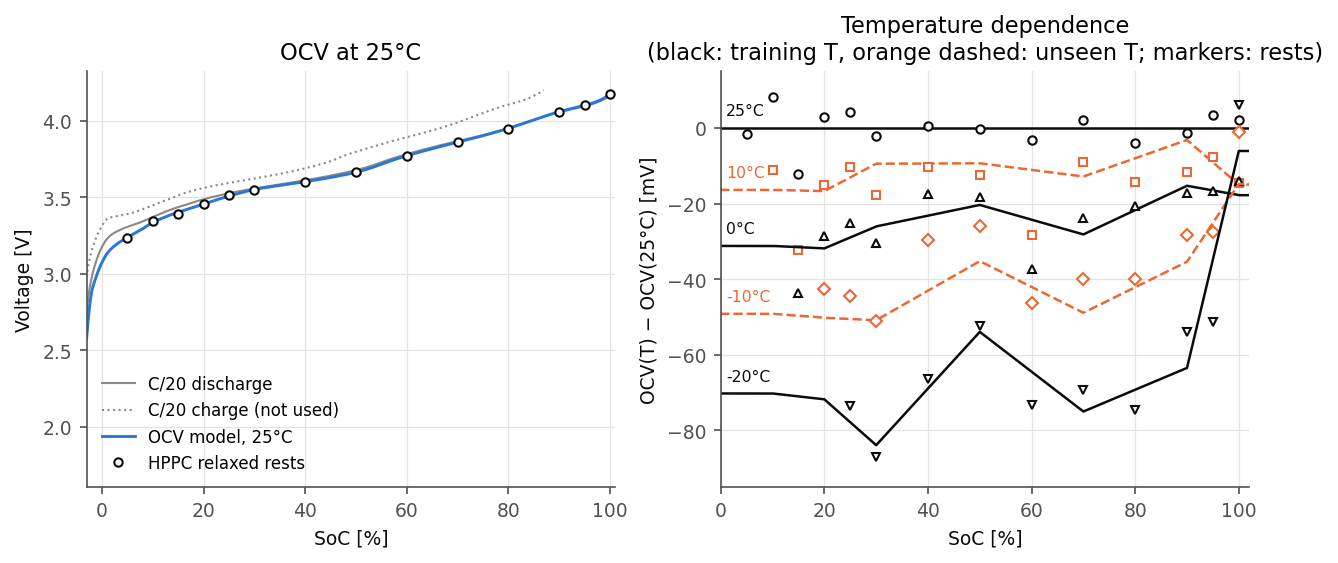

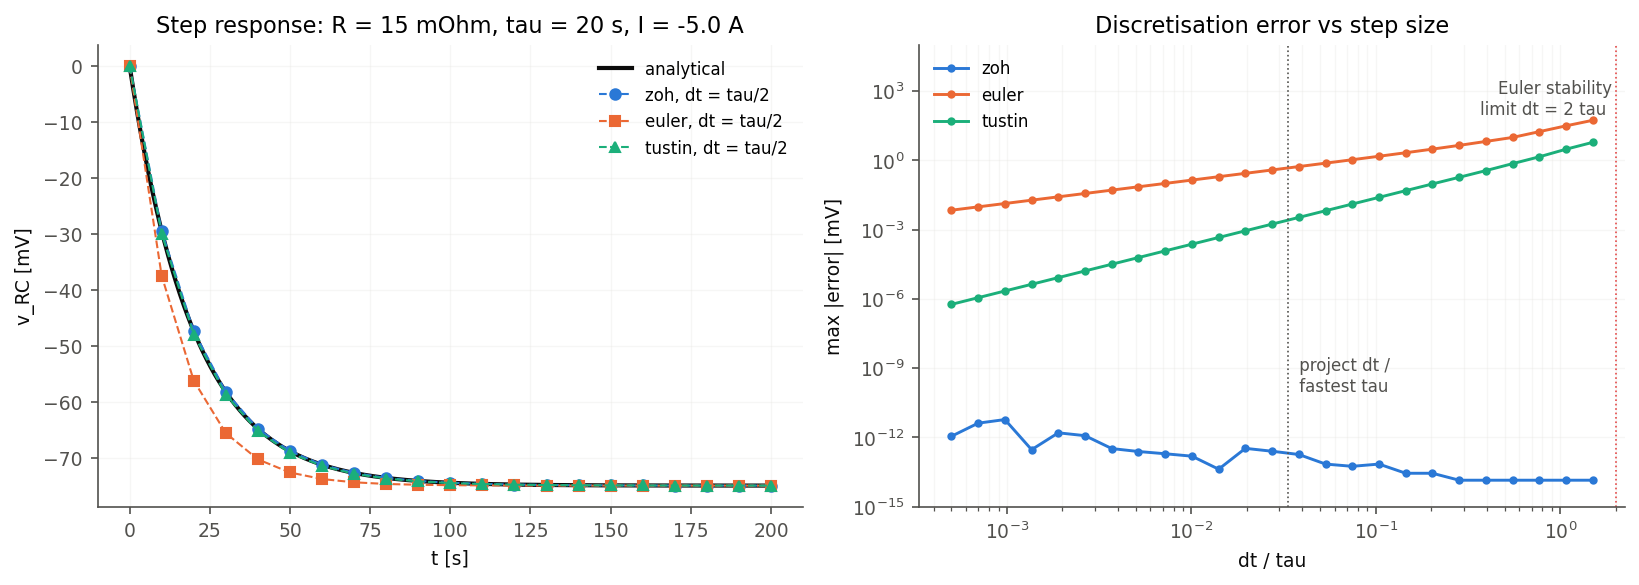

In [2]:
display(Image(R / 'figures' / 'ocv.png'))
display(Image(R / 'figures' / 'integrator_verification.png'))

| ECM voltage RMSE [mV] | 25 °C | 10 °C | 0 °C | -10 °C | -20 °C |
|---|---|---|---|---|---|
| 1-RC | 36.0 | 40.0 | 51.4 | 47.4 | 67.0 |
| 2-RC | 27.3 | 27.2 | 35.4 | 38.2 | 52.2 |
| 3-RC | 20.6 | 25.1 | 30.3 | 37.0 | 46.3 |

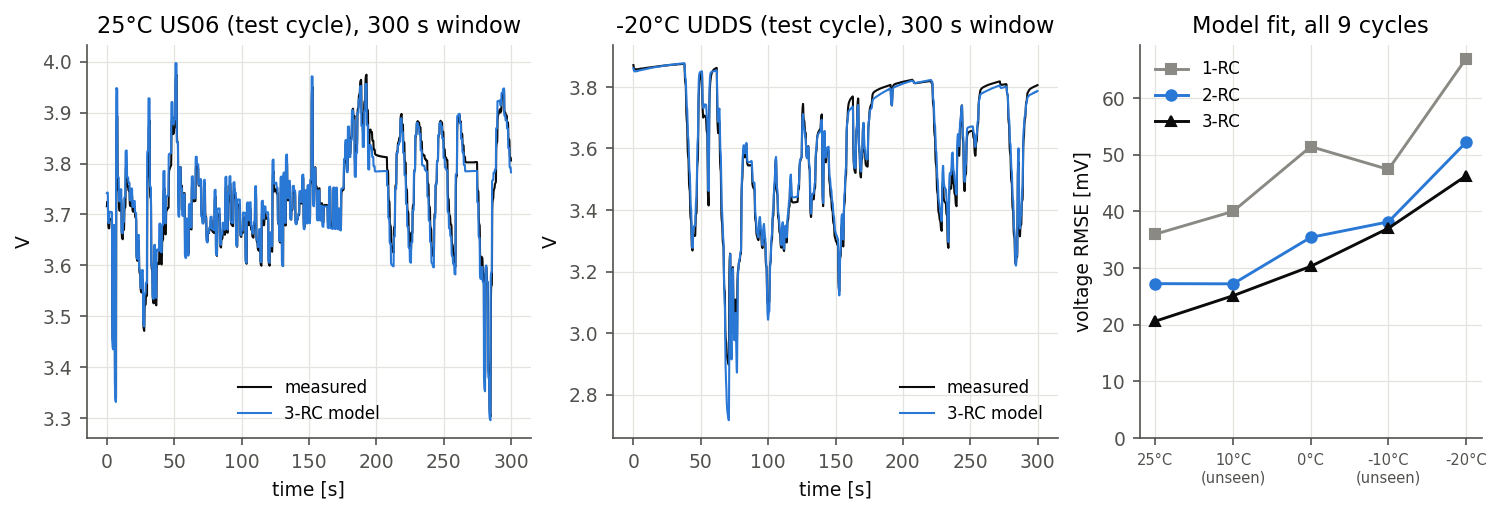

In [3]:
rows = []
for n in (1, 2, 3):
    p = R / f'ecm_fit_{n}rc.json'
    if p.exists():
        d = load(p.name)
        rows.append([f'{n}-RC'] + [f"{np.mean([v for k, v in d['rmse_mV'].items() if k.startswith(f'{T}C_')]):.1f}" for T in TEMPS])
table(rows, ['ECM voltage RMSE [mV]'] + [f'{T} °C' for T in TEMPS])
display(Image(R / 'figures' / 'voltage_fit.png'))

## 2. Accuracy and robustness on the test set

Selected on validation: **EKF 3-RC** (validation RMSE by order: 1-RC 2.40%, 2-RC 1.45%, 3-RC 1.07%); **LSTM-32, 100 s BPTT window**.

| Realistic sensors: test RMSE [%] | 25 °C | 10 °C (unseen) | 0 °C | -10 °C (unseen) | -20 °C |
|---|---|---|---|---|---|
| Coulomb counting | 8.83 | 8.92 | 9.35 | 9.47 | 9.58 |
| EKF 1-RC | 3.06 | 2.88 | 3.13 | 3.41 | 4.46 |
| EKF 2-RC | 1.24 | 1.10 | 1.89 | 2.62 | 2.89 |
| EKF 3-RC (selected) | 1.30 | 1.65 | 1.48 | 2.21 | 3.40 |
| Selected LSTM, mean of 3 seeds | 1.23 | 1.60 | 1.70 | 2.86 | 2.42 |
|    seed range | 1.18-1.31 | 1.30-1.95 | 1.56-1.81 | 2.46-3.61 | 2.33-2.57 |
| Selected LSTM, 3-seed ensemble | 1.08 | 1.38 | 1.59 | 2.61 | 2.04 |
| LSTM-32, 500 s window | 1.16 | 1.48 | 1.77 | 3.02 | 3.49 |
| GRU-32, 500 s window | 1.45 | 1.97 | 2.23 | 3.63 | 4.36 |

| Worst error after 10 min [%] | 25 °C | 10 °C | 0 °C | -10 °C | -20 °C |
|---|---|---|---|---|---|
| EKF 3-RC | 3.2 | 5.1 | 2.8 | 5.1 | 8.8 |
| Selected LSTM, seed 0 | 4.9 | 4.3 | 4.8 | 7.7 | 8.1 |

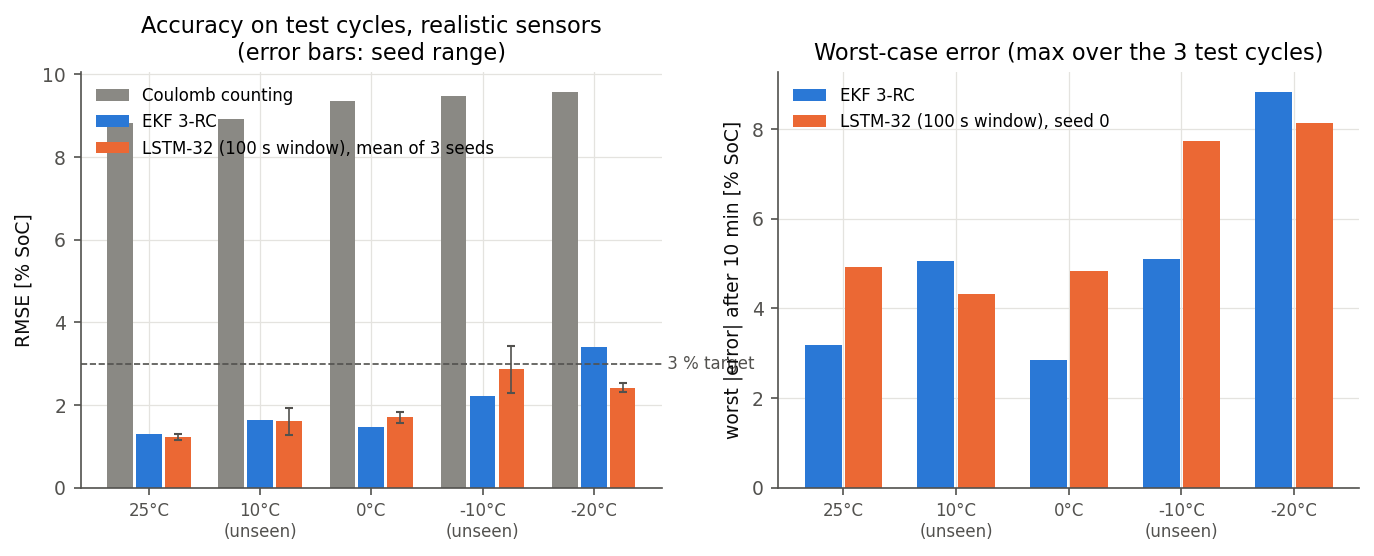

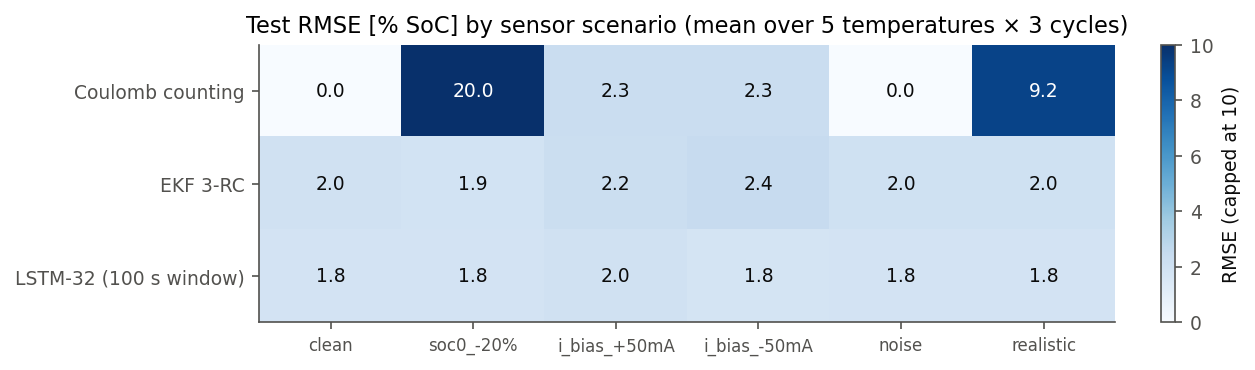

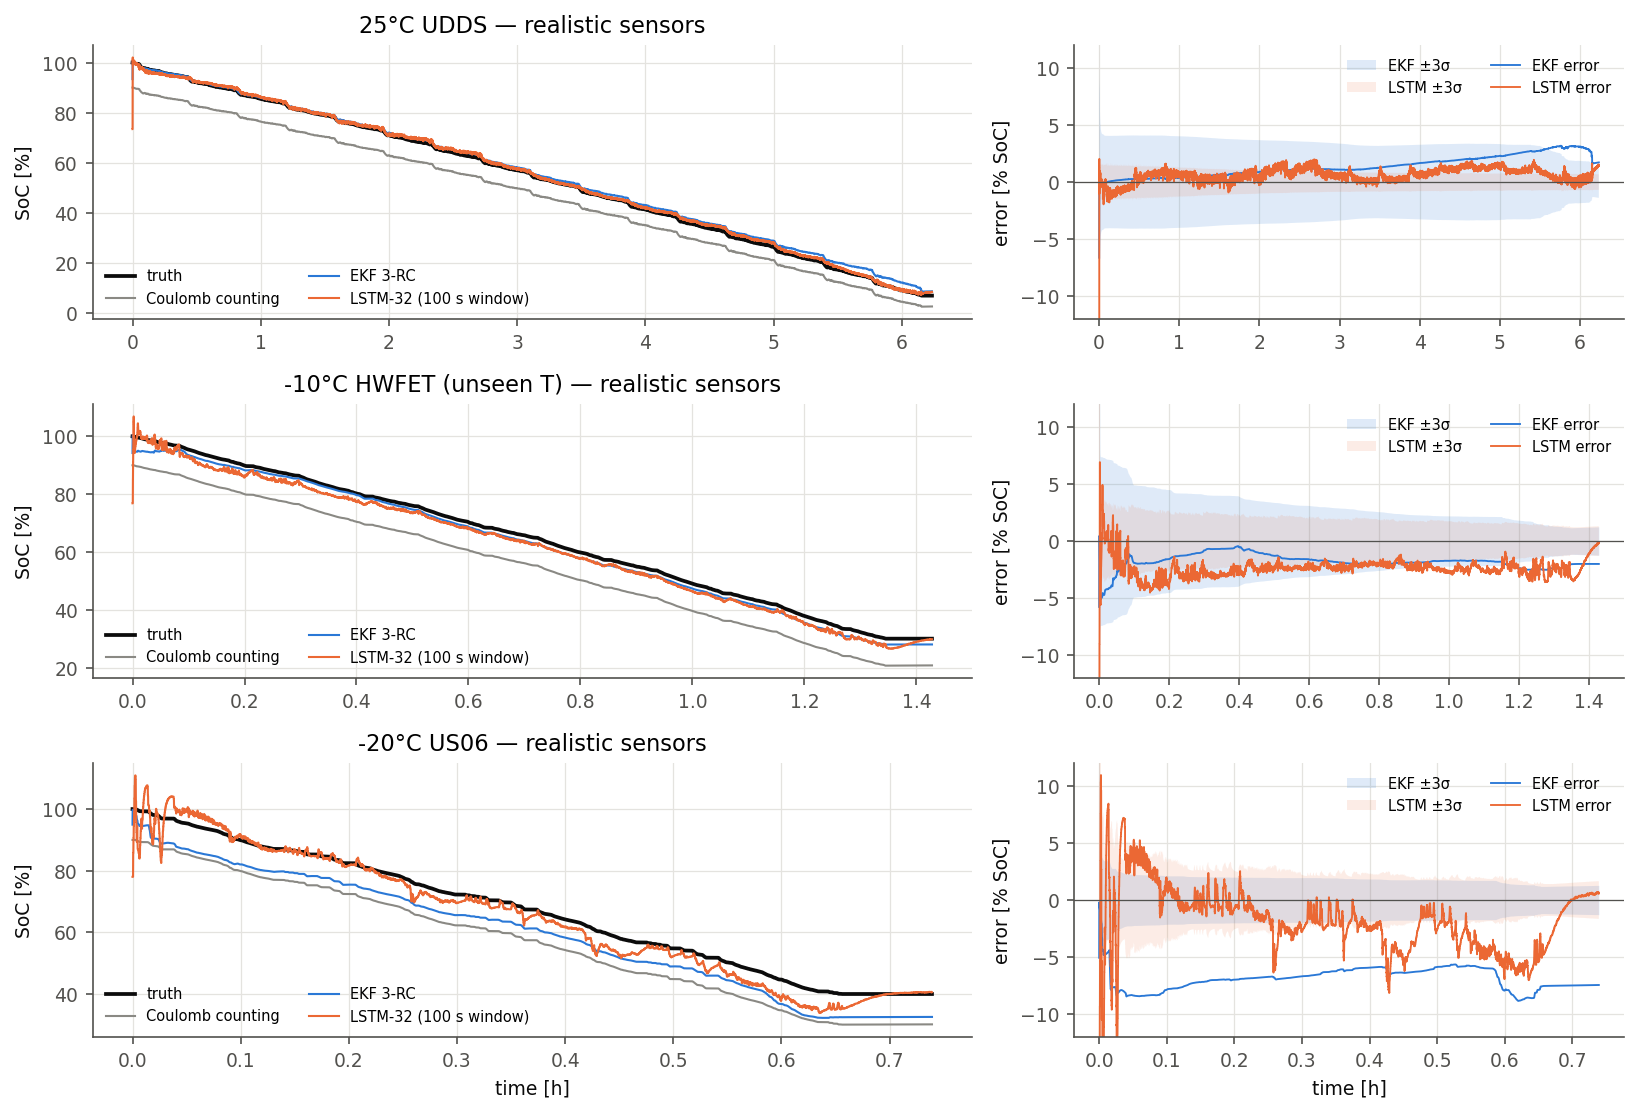

In [4]:
ekf_n = load('ekf_selected.json')['n_rc']; sel = load('ml_selected.json')
display(Markdown(f"Selected on validation: **EKF {ekf_n}-RC** (validation RMSE by order: "
                 + ', '.join(f"{k}-RC {v:.2f}%" for k, v in load('ekf_selected.json')['validation_rmse'].items())
                 + f"); **{sel['config'][0].upper()}-{sel['config'][1]}, {sel['config'][2]} s BPTT window**."))
cc = load(f'ekf_{ekf_n}rc_eval.json')['results']
rows = [['Coulomb counting'] + [f'{x:.2f}' for x in by_T(cc, 'coulomb')]]
for n in (1, 2, 3):
    d = load(f'ekf_{n}rc_eval.json')['results']
    rows.append([f'EKF {n}-RC' + (' (selected)' if n == ekf_n else '')] + [f'{x:.2f}' for x in by_T(d, 'ekf')])
seeds = [load(f'ml_{t}_eval.json')['results'] for t in sel['seeds']]
S = np.array([by_T(s, 'lstm') for s in seeds])
rows.append(['Selected LSTM, mean of 3 seeds'] + [f'{x:.2f}' for x in S.mean(0)])
rows.append(['   seed range'] + [f'{a:.2f}-{b:.2f}' for a, b in zip(S.min(0), S.max(0))])
d = load(f"ml_{sel['ensemble']}_eval.json")['results']
rows.append(['Selected LSTM, 3-seed ensemble'] + [f'{x:.2f}' for x in by_T(d, d[0]['method'])])
for f, lab in [('ml_lstm32_c500_s0_eval.json', 'LSTM-32, 500 s window'), ('ml_gru32_c500_s0_eval.json', 'GRU-32, 500 s window')]:
    d = load(f)['results']
    rows.append([lab] + [f'{x:.2f}' for x in by_T(d, d[0]['method'])])
table(rows, ['Realistic sensors: test RMSE [%]'] + [f'{T} °C' + ('' if T in (25, 0, -20) else ' (unseen)') for T in TEMPS])
ekf = load(f'ekf_{ekf_n}rc_eval.json')['results']; ml = seeds[0]
rows = [[lab] + [f'{x:.1f}' for x in by_T(res, p, key='maxabs_settled', agg=np.max)] for lab, res, p in
        [(f'EKF {ekf_n}-RC', ekf, 'ekf'), ('Selected LSTM, seed 0', ml, 'lstm')]]
table(rows, ['Worst error after 10 min [%]'] + [f'{T} °C' for T in TEMPS])
display(Image(R / 'figures' / 'accuracy_by_temperature.png'))
display(Image(R / 'figures' / 'robustness.png'))
display(Image(R / 'figures' / 'trajectories.png'))

## 3. Physical constraints and uncertainty

In [5]:
rows = []
for lab, res, p in [(f'EKF {ekf_n}-RC', ekf, 'ekf'), ('Selected LSTM, seed 0', ml, 'lstm')]:
    rr = [r for r in res if r['method'].startswith(p)]
    rows.append([lab, f"{100*np.mean([r['frac_outside_01'] for r in rr]):.2f}",
                 f"{np.mean([abs(r['unexplained_dsoc']) for r in rr if r['scenario'] == 'clean']):.2f}",
                 f"{100*np.mean([r['coverage_3sig_raw'] for r in rr]):.0f}",
                 f"{100*np.mean([r['coverage_3sig'] for r in rr]):.0f}"])
table(rows, ['', '% estimates outside [0,1]', 'mean |unexplained ΔSoC| on clean data [%]', '3σ coverage raw %', '3σ coverage calibrated %'])

|  | % estimates outside [0,1] | mean |unexplained ΔSoC| on clean data [%] | 3σ coverage raw % | 3σ coverage calibrated % |
|---|---|---|---|---|
| EKF 3-RC | 0.46 | 2.31 | 78 | 75 |
| Selected LSTM, seed 0 | 1.20 | 24.43 | 86 | 55 |

## 4. Optimisation, sensitivity and cost

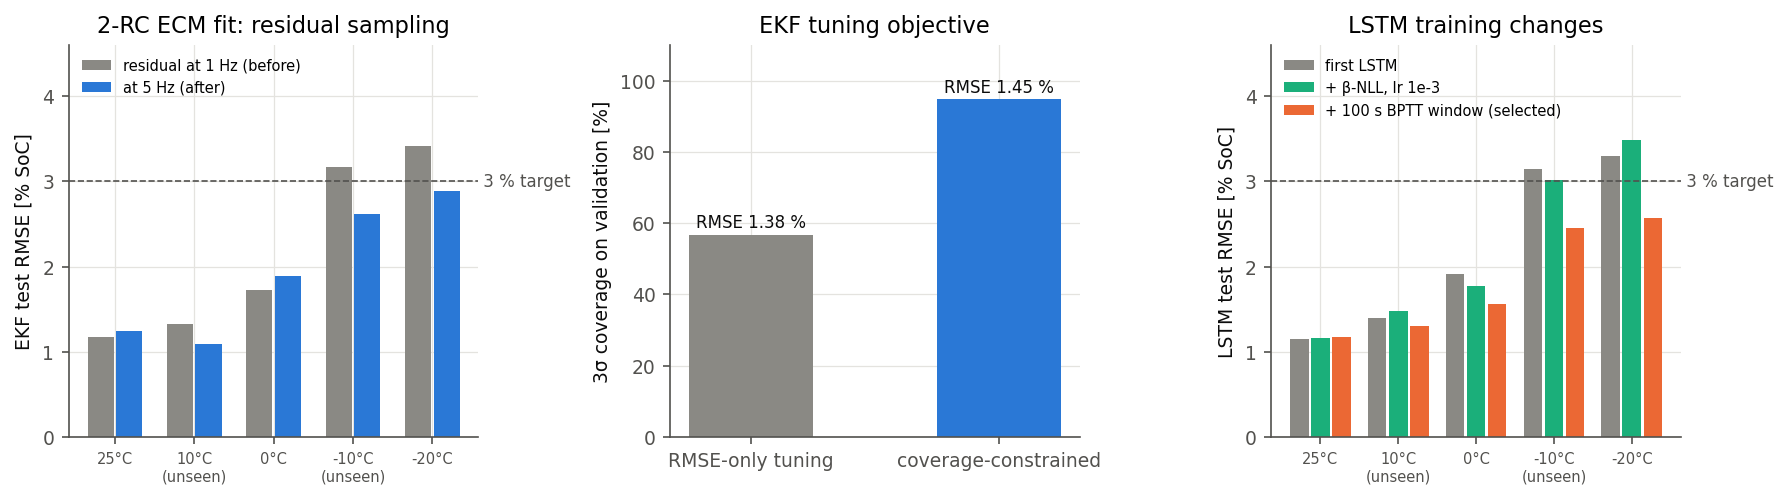

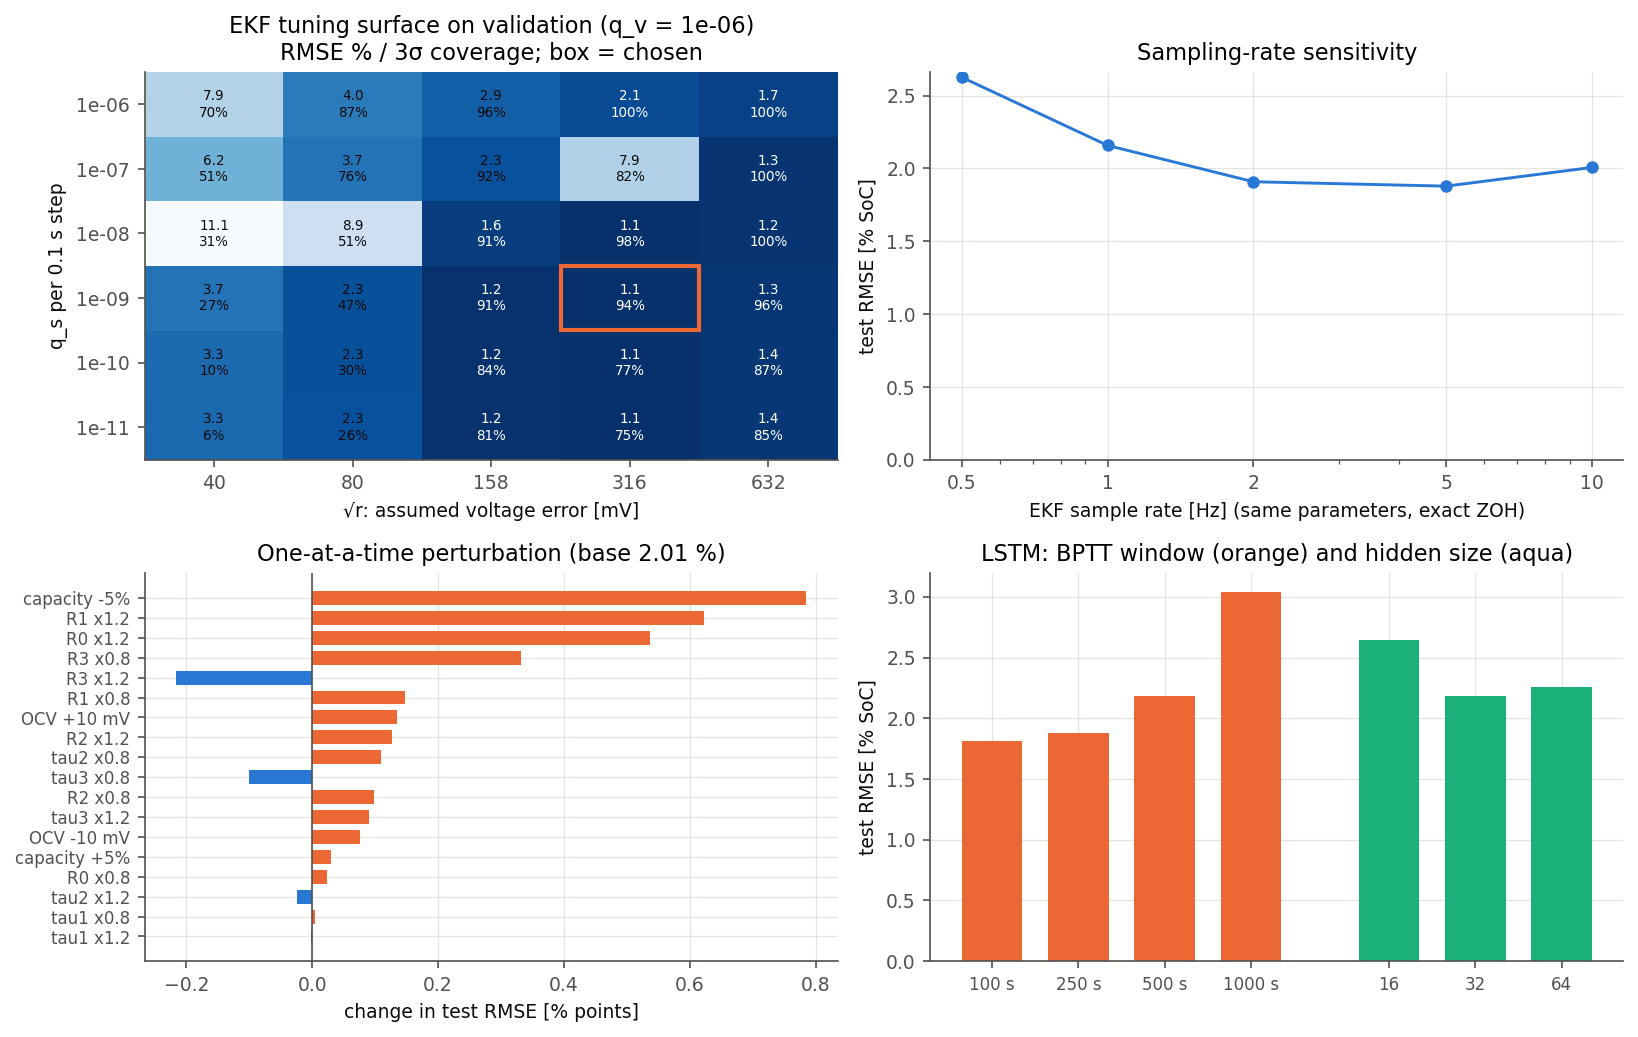

| model | Hz | FLOP/step | FLOP/s | params | FLOP/byte | µs/step (PC) | µs/step (MCU est.) |
|---|---|---|---|---|---|---|---|
| ekf_1rc | 10 | 218 | 2180 | 3330 | 0.70 | 0.12 | 3.1 |
| ekf_2rc | 10 | 460 | 4600 | 3348 | 0.91 | 0.20 | 5.6 |
| ekf_3rc | 10 | 860 | 8600 | 3366 | 1.21 | 0.31 | 9.0 |
| lstm16 | 1 | 2704 | 2704 | 1378 | 0.48 | 0.85 | 45.0 |
| lstm32 | 1 | 9504 | 9504 | 4802 | 0.49 | 2.61 | 114.1 |
| lstm64 | 1 | 35392 | 35392 | 17794 | 0.49 | 10.05 | 325.3 |
| gru32 | 1 | 7232 | 7232 | 3618 | 0.50 | nan | 77.7 |

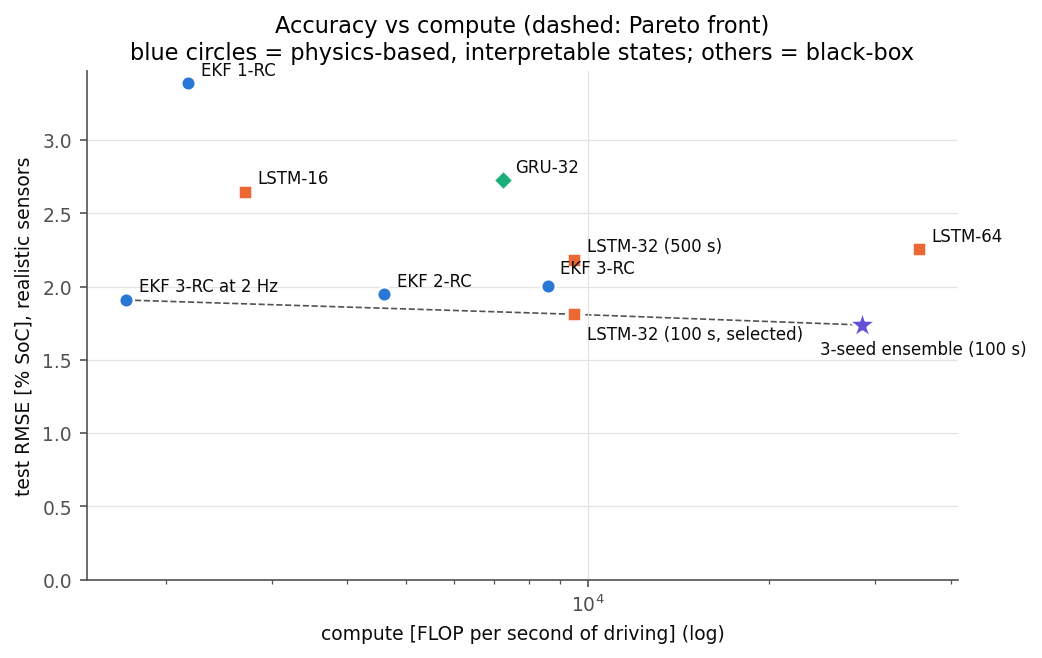

In [6]:
display(Image(R / 'figures' / 'before_after.png'))
display(Image(R / 'figures' / 'sensitivity.png'))
perf = load('perf.json')['models']
rows = [[k, str(v['rate_hz']), str(v['flops']), str(v['flops_per_s']), str(v['params_total']),
         f"{v['arith_intensity']:.2f}", f"{v.get('us_per_step', float('nan')):.2f}", f"{v['mcu_us_per_step']:.1f}"]
        for k, v in perf.items()]
table(rows, ['model', 'Hz', 'FLOP/step', 'FLOP/s', 'params', 'FLOP/byte', 'µs/step (PC)', 'µs/step (MCU est.)'])
display(Image(R / 'figures' / 'pareto.png'))